# Задача 2.1

Сравнение параметров:
Теоретическое среднее:     40.0000 | Выборочное среднее:     40.0448 (разница: +0.0448)
Теоретическое ст. откл.:   8.0000 | Выборочное ст. откл.:   7.9718 (разница: -0.0282)


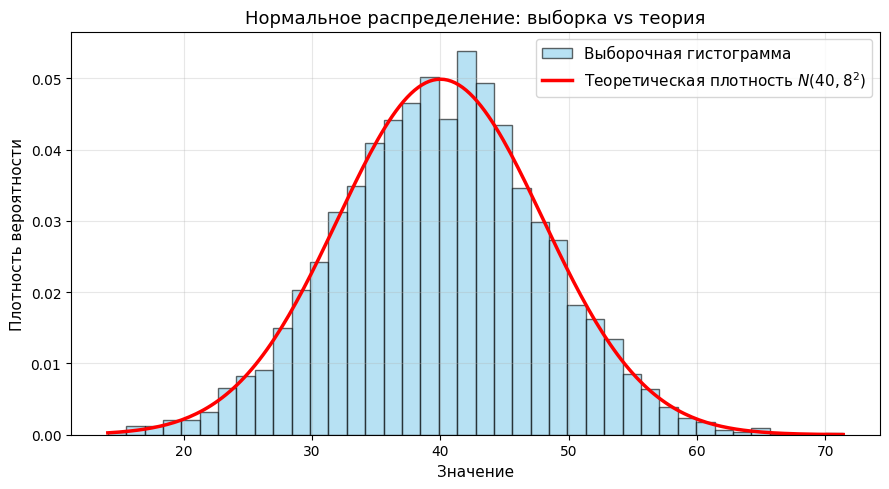

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

mu_true = 40
sigma_true = 8
n_samples = 5000

np.random.seed(42)
sample_norm = np.random.normal(loc=mu_true, scale=sigma_true, size=n_samples)

sample_mean = np.mean(sample_norm)
sample_std = np.std(sample_norm, ddof=1)

print("Сравнение параметров:")
print(f"Теоретическое среднее:     {mu_true:.4f} | Выборочное среднее:     {sample_mean:.4f} (разница: {sample_mean - mu_true:+.4f})")
print(f"Теоретическое ст. откл.:   {sigma_true:.4f} | Выборочное ст. откл.:   {sample_std:.4f} (разница: {sample_std - sigma_true:+.4f})")

plt.figure(figsize=(9, 5))
count, bins, _ = plt.hist(
    sample_norm,
    bins=40,
    density=True,
    alpha=0.6,
    color="skyblue",
    edgecolor="black",
    label="Выборочная гистограмма",
)

x = np.linspace(bins[0], bins[-1], 200)
pdf_theoretical = stats.norm.pdf(x, loc=mu_true, scale=sigma_true)
plt.plot(x, pdf_theoretical, "r-", lw=2.5, label=f"Теоретическая плотность $N({mu_true}, {sigma_true}^2)$")

plt.title("Нормальное распределение: выборка vs теория", fontsize=13)
plt.xlabel("Значение", fontsize=11)
plt.ylabel("Плотность вероятности", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Задача 2.2

Сравнение параметров:
Теоретическое среднее:     40.0000 | Выборочное среднее:     40.1998 (разница: +0.1998)
Теоретическое ст. откл.:   6.1968 | Выборочное ст. откл.:   6.1936 (разница: -0.0031)


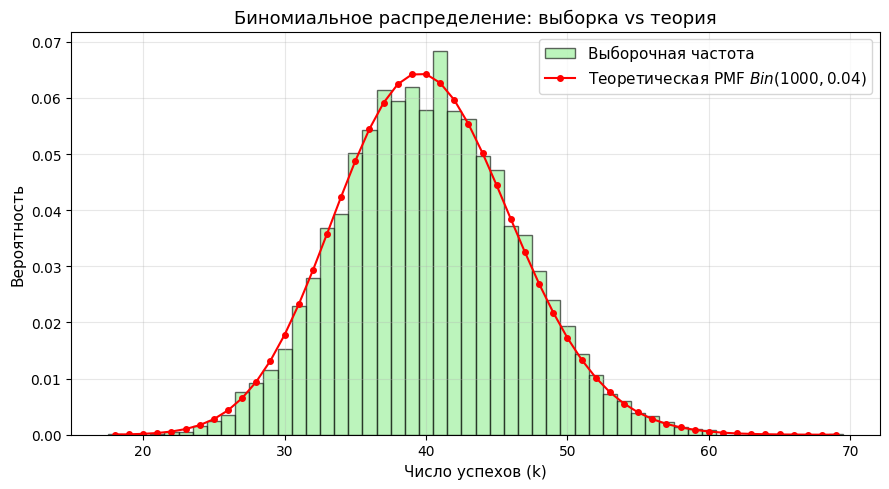

In [5]:
n_trials = 1000
p_true = 0.04
size = 5000

np.random.seed(42)
sample_binom = np.random.binomial(n=n_trials, p=p_true, size=size)

theor_mean = n_trials * p_true
theor_std = np.sqrt(n_trials * p_true * (1 - p_true))

sample_mean_binom = np.mean(sample_binom)
sample_std_binom = np.std(sample_binom, ddof=1)

print("Сравнение параметров:")
print(f"Теоретическое среднее:     {theor_mean:.4f} | Выборочное среднее:     {sample_mean_binom:.4f} (разница: {sample_mean_binom - theor_mean:+.4f})")
print(f"Теоретическое ст. откл.:   {theor_std:.4f} | Выборочное ст. откл.:   {sample_std_binom:.4f} (разница: {sample_std_binom - theor_std:+.4f})")

plt.figure(figsize=(9, 5))
bins = np.arange(sample_binom.min() - 0.5, sample_binom.max() + 1.5, 1)

plt.hist(
    sample_binom,
    bins=bins,
    density=True,
    alpha=0.6,
    color="lightgreen",
    edgecolor="black",
    label="Выборочная частота",
)

k_values = np.arange(sample_binom.min(), sample_binom.max() + 1)
pmf_values = stats.binom.pmf(k_values, n=n_trials, p=p_true)
plt.plot(k_values, pmf_values, "ro-", markersize=4, lw=1.5, label=f"Теоретическая PMF $Bin({n_trials}, {p_true})$")

plt.title("Биномиальное распределение: выборка vs теория", fontsize=13)
plt.xlabel("Число успехов (k)", fontsize=11)
plt.ylabel("Вероятность", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Задача 2.3

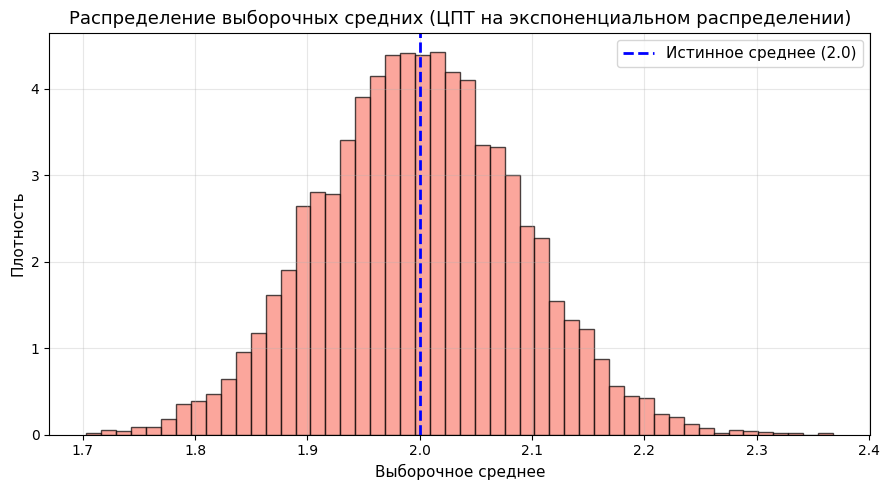

In [7]:
sample_size = 500
n_simulations = 10000
scale_param = 2.0

np.random.seed(42)
samples = np.random.exponential(scale=scale_param, size=(n_simulations, sample_size))
means = samples.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.hist(means, bins=50, density=True, color="salmon", edgecolor="black", alpha=0.7)
plt.axvline(scale_param, color="blue", linestyle="--", lw=2, label=f"Истинное среднее ({scale_param})")

plt.title("Распределение выборочных средних (ЦПТ на экспоненциальном распределении)", fontsize=13)
plt.xlabel("Выборочное среднее", fontsize=11)
plt.ylabel("Плотность", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Описание результатов:
# На графике видна симметричная колоколообразная форма нашего распределения
# Несмотря на то что само распределение асимметрично и сильно скошено вправо,
# распределение выборочных средних при достаточно большом n стремится к нормальному
# в строгом соответствии с ЦПТ м

# Задача 3.1

In [9]:
n_old, k_old = 5000, 155
n_new, k_new = 5000, 170

p_old = k_old / n_old
p_new = k_new / n_new
delta_p = p_new - p_old

se_old = np.sqrt(p_old * (1 - p_old) / n_old)
se_new = np.sqrt(p_new * (1 - p_new) / n_new)

se_diff = np.sqrt(se_old**2 + se_new**2)

print("Задание 3.1. Результаты расчёта по формуле:")
print(f"Старая кнопка: p1 = {p_old:.1%}, SE1 = {se_old:.4f} ({se_old * 100:.2f} п.п.)")
print(f"Новая кнопка:  p2 = {p_new:.1%}, SE2 = {se_new:.4f} ({se_new * 100:.2f} п.п.)")
print(f"Разница конверсий: {delta_p * 100:.2f} п.п. ({delta_p:.4f})")
print(f"Стандартная ошибка разности: {se_diff * 100:.2f} п.п. ({se_diff:.4f})")

# Предварительный вывод:
# Наблюдаемая разница (0,30 пп) сопоставима со стандартной ошибкой каждой группы (~0,25 пп)
# и меньше стандартной ошибки разности двух долей (0,35 пп)
# Разница не превышает даже одну стандартную ошибку, поэтому наблюдаемый прирост
# с высокой вероятностью является шшумом, а не реальным эффектом

Задание 3.1. Результаты расчёта по формуле:
Старая кнопка: p1 = 3.1%, SE1 = 0.0025 (0.25 п.п.)
Новая кнопка:  p2 = 3.4%, SE2 = 0.0026 (0.26 п.п.)
Разница конверсий: 0.30 п.п. (0.0030)
Стандартная ошибка разности: 0.35 п.п. (0.0035)


# Задача 3.2

Результаты симуляции:
Доля симуляций с разницей >= 0.3 п.п. (односторонний p-value): 18.9%
Доля симуляций с отклонением >= |0.3| п.п. (двусторонний p-value): 37.9%


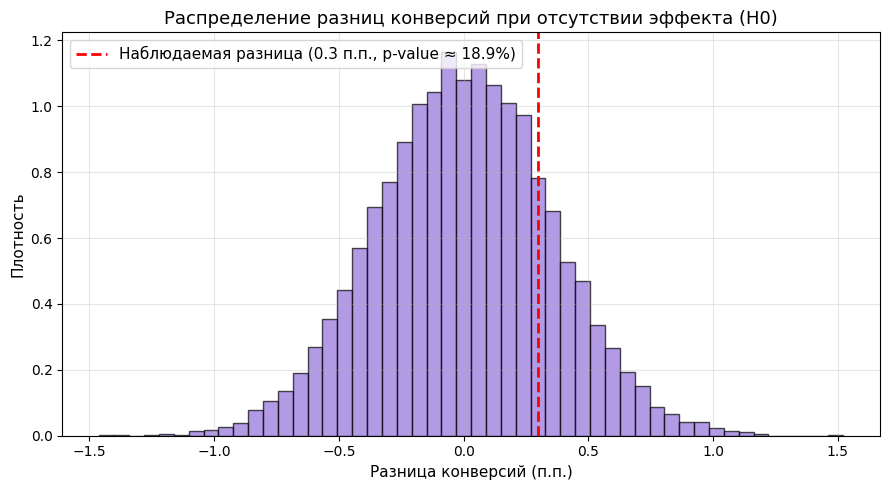

In [12]:
n_users = 5000
total_clicks = 155 + 170
total_users = 5000 + 5000
p_pool = total_clicks / total_users

observed_diff = 0.034 - 0.031
n_sim = 20000

np.random.seed(42)
clicks_group_a = np.random.binomial(n=n_users, p=p_pool, size=n_sim)
clicks_group_b = np.random.binomial(n=n_users, p=p_pool, size=n_sim)

diffs = (clicks_group_b - clicks_group_a) / n_users

p_value_one_sided = np.mean(diffs >= observed_diff)
p_value_two_sided = np.mean(np.abs(diffs) >= observed_diff)

print("Результаты симуляции:")
print(f"Доля симуляций с разницей >= 0.3 п.п. (односторонний p-value): {p_value_one_sided:.1%}")
print(f"Доля симуляций с отклонением >= |0.3| п.п. (двусторонний p-value): {p_value_two_sided:.1%}")

plt.figure(figsize=(9, 5))
plt.hist(diffs * 100, bins=50, density=True, color="mediumpurple", edgecolor="black", alpha=0.7)
plt.axvline(observed_diff * 100, color="red", linestyle="--", lw=2,
            label=f"Наблюдаемая разница (0.3 п.п., p-value ≈ {p_value_one_sided:.1%})")

plt.title("Распределение разниц конверсий при отсутствии эффекта (H0)", fontsize=13)
plt.xlabel("Разница конверсий (п.п.)", fontsize=11)
plt.ylabel("Плотность", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Ответ:
# Это ШУМ. Случайная разница в 0,3 п.п. или более возникает примерно в 20% случаев
# даже тогда, когда между кнопками нет никакой реальной разницы
# Оснований утверждать, что новая кнопка работает лучш нет

# Задача 3.3

In [18]:
sessions = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

mean_val = np.mean(sessions)
std_val = np.std(sessions, ddof=1)

lower_3sigma = mean_val - 3 * std_val
upper_3sigma = mean_val + 3 * std_val

outliers_3sigma = sessions[(sessions < lower_3sigma) | (sessions > upper_3sigma)]

q25, q75 = np.percentile(sessions, [25, 75])
iqr = q75 - q25

lower_iqr = q25 - 1.5 * iqr
upper_iqr = q75 + 1.5 * iqr

outliers_iqr = sessions[(sessions < lower_iqr) | (sessions > upper_iqr)]

print("Анализ выбросов:")
print(f"Выборка: {list(sessions)}")
print("-" * 67)
print(f"Правило 3 сигм:")
print(f"  Среднее: {mean_val:.2f}, Ст. откл.: {std_val:.2f}")
print(f"  Допустимый интервал: [{lower_3sigma:.2f}, {upper_3sigma:.2f}]")
print(f"  Найденные выбросы: {list(outliers_3sigma)}")
print("-" * 67)
print(f"Метод перцентилей (IQR):")
print(f"  Q1 (25%): {q25:.2f}, Q3 (75%): {q75:.2f}, IQR: {iqr:.2f}")
print(f"  Допустимый интервал: [{lower_iqr:.2f}, {upper_iqr:.2f}]")
print(f"  Найденные выбросы: {list(outliers_iqr)}")

# Сравнение и объяснение:
# Правило трёх сигм не обнаружило значение 52 как выброс (верхняя граница получилась 54.50 > 52)
# Причина: среднее арифметическое и стандартное отклонение не устойчивы к экстремальным значениям
# На маленькой выборке из 10 элементов одно аномальное значение 52 само раздуло среднее (до 10)
# и стандартное отклонение (до 14.83), тем самым искусственно расширив границы интервала
# Метод перцентилей (IQR) сработал лучше: он корректно выделил 52 как выброс (граница 10.5)
# Квартили и медиана устойчивы к единичным экстремальным выбросам, поэтому данный метод
# надёжен даже на малых и скошенных выборках

Анализ выбросов:
Выборка: [np.int64(3), np.int64(4), np.int64(4), np.int64(5), np.int64(5), np.int64(6), np.int64(6), np.int64(7), np.int64(8), np.int64(52)]
-------------------------------------------------------------------
Правило 3 сигм:
  Среднее: 10.00, Ст. откл.: 14.83
  Допустимый интервал: [-34.50, 54.50]
  Найденные выбросы: []
-------------------------------------------------------------------
Метод перцентилей (IQR):
  Q1 (25%): 4.25, Q3 (75%): 6.75, IQR: 2.50
  Допустимый интервал: [0.50, 10.50]
  Найденные выбросы: [np.int64(52)]
